# Visualisation with Matplotlib and seaborn — worked solutions

Explore demographic indicators with line charts, bar charts, scatter plots, and histograms.

Run cells in order with **Shift + Enter**. Each notebook needs its own imports and definitions.


## Data and research context

`data/wdi_population.csv` contains eight countries at four selected years: 2010, 2015, 2020, and 2023.
One row is a **country-year**. This is a fixed extract of published World Bank indicators.
`population` is a count; `share_65_plus` and `urban_share` are percentages; `life_expectancy` is
life expectancy **at birth**, in years, not the average age of people who died.

These countries are not a representative sample of the world. Country-level patterns do not establish
individual-level relationships or causal effects. Derived older population counts are approximate.
See `data/DATA_NOTE_EN.txt` for definitions and provenance.

Sources: [population](https://data.worldbank.org/indicator/SP.POP.TOTL),
[65+ share](https://data.worldbank.org/indicator/SP.POP.65UP.TO.ZS),
[life expectancy](https://data.worldbank.org/indicator/SP.DYN.LE00.IN),
[urban share](https://data.worldbank.org/indicator/SP.URB.TOTL.IN.ZS).


## VIS-01 · Start a reproducible plotting notebook

Import pandas, matplotlib.pyplot as plt, and seaborn as sns.
Read data/wdi_population.csv and select the 2023 snapshot.
Set a simple seaborn theme. This notebook must run independently of the previous notebooks.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("data/wdi_population.csv")
snapshot = df.loc[df["year"] == 2023].copy()
sns.set_theme(style="whitegrid")

## VIS-02 · Matplotlib: population ageing over time

Select Japan using country_code JPN and sort its observations by year.
Make a Matplotlib line chart of share_65_plus against year, with a marker at each observed year.
Label both axes, include the country and source in the title, and display the figure.
Explain that lines connect four selected observations; they do not show every intervening year.


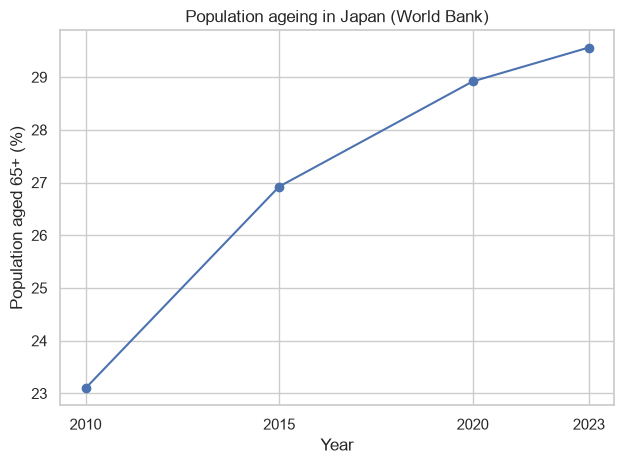

In [2]:
japan = df.loc[df["country_code"] == "JPN"].sort_values("year")

fig, ax = plt.subplots()
ax.plot(japan["year"], japan["share_65_plus"], marker="o")
ax.set_xticks(japan["year"])
ax.set_xlabel("Year")
ax.set_ylabel("Population aged 65+ (%)")
ax.set_title("Population ageing in Japan (World Bank)")
fig.tight_layout()
plt.show()

The share aged 65+ rose from 23.1% in 2010 to 29.6% in 2023. The markers show the four observed years. The line segments connect those observations.

## VIS-03 · Seaborn: compare countries in the same year

Sort the 2023 snapshot by share_65_plus. Make a horizontal bar chart with seaborn:
older population share on x, country on y. Use one colour, descriptive labels, and a zero baseline.
There is one record per country in the snapshot, so disable an estimated error bar.
State the year and that these are selected countries, not all countries in the world.


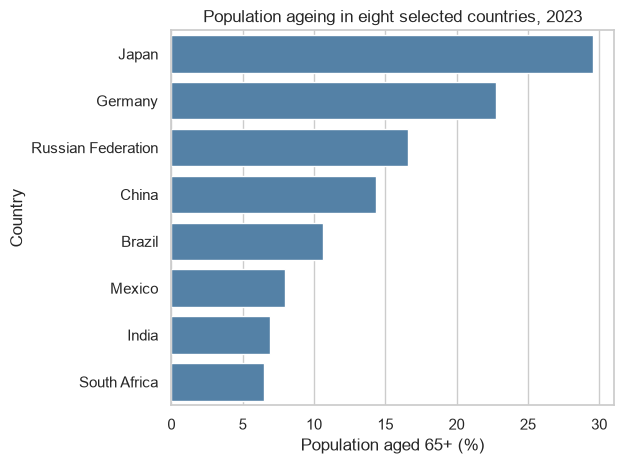

In [3]:
ordered = snapshot.sort_values("share_65_plus", ascending=False)
fig, ax = plt.subplots()
sns.barplot(data=ordered, x="share_65_plus", y="country", order=ordered["country"],
            color="steelblue", errorbar=None, ax=ax)
ax.set_xlim(left=0)
ax.set_xlabel("Population aged 65+ (%)")
ax.set_ylabel("Country")
ax.set_title("Population ageing in eight selected countries, 2023")
fig.tight_layout()
plt.show()

## VIS-04 · A scatter plot and a careful interpretation

In the 2023 snapshot, plot share_65_plus on x and life_expectancy on y using sns.scatterplot.
Give both axes units and give the plot a title. One point should represent one country.
Write one sentence about the visible pattern and one sentence explaining why this chart does not
identify a causal effect or describe the relationship between individuals.
Use the same figure / axes pattern as above.


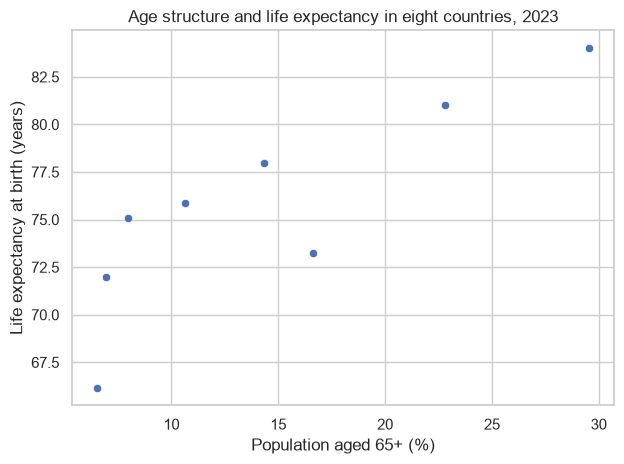

In [4]:
fig, ax = plt.subplots()
sns.scatterplot(data=snapshot, x="share_65_plus", y="life_expectancy", ax=ax)
ax.set_xlabel("Population aged 65+ (%)")
ax.set_ylabel("Life expectancy at birth (years)")
ax.set_title("Age structure and life expectancy in eight countries, 2023")
fig.tight_layout()
plt.show()

Across these eight countries in 2023, those with larger shares of older residents generally had higher life expectancy at birth. Each point summarises an entire country, and other factors can affect both indicators, so this comparison cannot establish causality or an individual-level relationship.

# Additional exercises


## VIS-X1 · The distribution of ages in Adult

Read data/adult.data.csv with ? as missing. Use sns.histplot to display age with 20 bins.
Label the horizontal axis as age in years and the vertical axis as record count.
Explain how a histogram differs from a bar chart of categories.
The figure describes the historical, unweighted Adult sample, not today's population.


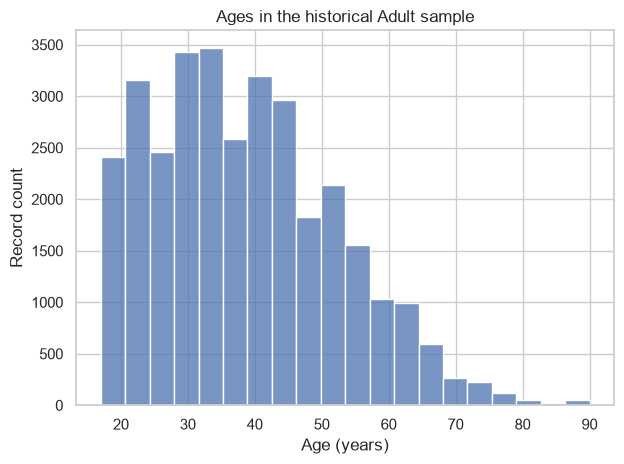

In [5]:
adult = pd.read_csv("data/adult.data.csv", na_values="?")

fig, ax = plt.subplots()
sns.histplot(data=adult, x="age", bins=20, ax=ax)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Record count")
ax.set_title("Ages in the historical Adult sample")
fig.tight_layout()
plt.show()

Each bin covers a range of ages and its height counts the sample records in that range. A categorical bar chart gives each named group its own bar.

## VIS-X2 · Save a figure

Save the current figure to outputs/age_distribution.png at 150 dpi with tight bounds.
Use fig.savefig so that the figure object is explicit. Rerunning replaces this output file.


In [6]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
fig.savefig(output_dir / "age_distribution.png", dpi=150, bbox_inches="tight")

## Save and check

Save the completed notebook, restart the kernel, and run from the top. Keep the data folder beside the notebooks.
